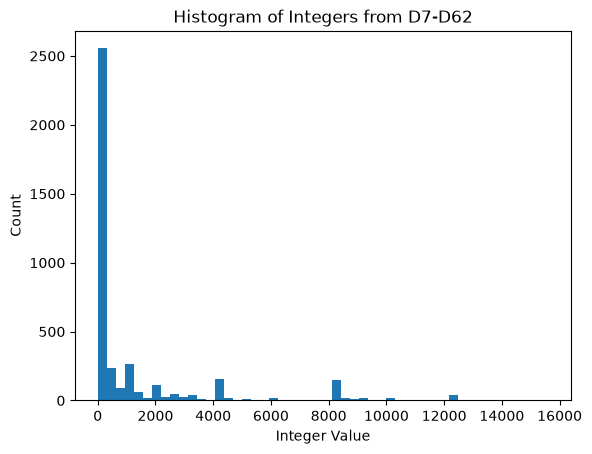

In [8]:
#import the generated.csv file and do histograms over the columns
import numpy as np
import matplotlib.pyplot as plt
N=1000

with open("generated.csv", "r") as f:
    lines = f.readlines()
    header = lines[0].strip().split(",")[2:]
    data_raw = np.array([list(map(int, line.strip().split(",")[2:])) for line in lines[1:N+1]])
    data_basis = np.array([list(map(str, line.strip().split(",")[1:2])) for line in lines[1:N+1]])
    #sort data_raw into "X" and "Z" basis
    data_X = data_raw[data_basis.flatten() == "X"]
    data_Z = data_raw[data_basis.flatten() == "Z"]
    

#first, take collumn D7-D62, and seperate it into bit strings of length 14. Do a histogram over the integers they represent
data_D7_D62 = data_raw[:, 5:58]  # D7 to D62 (0-indexed)
#bin each row (of length 53) into bit strings of length 14
bit_strings = []
for row in data_D7_D62:
    row_str = "".join(map(str, row))
    for i in range(0, len(row_str), 14):
        bit_strings.append(row_str[i:i+14])
integers = np.array([int(bit_string, 2) for bit_string in bit_strings])
plt.hist(integers, bins=50)
plt.title("Histogram of Integers from D7-D62")
plt.xlabel("Integer Value")
plt.ylabel("Count")
plt.show()